### Natural Language Processing - Assignment-1: Set-13

**Group Number:** 125

| Name | BITS ID |
| :--- | :--- |
| Saumyajeet Mohanty | 2025AG05436 |
| Suchintak Patnaik | 2025AG05930 |
| Malaya Sethi | 2025AG05448 |
| Ramineni Abhilash | 2025AG05668 |

**Dataset Link:** [UN General Debates (Kaggle)](https://www.kaggle.com/api/v1/datasets/download/unitednations/un-general-debates)

## Install libraries

In [2]:
!pip install -q gensim nltk scikit-learn pandas numpy matplotlib

## Import libraries

In [3]:
import re
import io
import zipfile
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk

from collections import Counter, defaultdict

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

from gensim.models import Word2Vec

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

## Download NLTK resources

In [4]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

## Load Kaggle Dataset from Kaggle URL

In [5]:
KAGGLE_URL = (
    "https://www.kaggle.com/api/v1/datasets/download/unitednations/un-general-debates"
)

response = requests.get(KAGGLE_URL)

response.raise_for_status()

print("Download successful")
print("Size:", round(len(response.content) / (1024 * 1024), 2), "MB")

Download successful
Size: 43.6 MB


## Display the files inside the Kaggle dataset zip folder

In [6]:
zip_data = zipfile.ZipFile(io.BytesIO(response.content))

print("Files available in dataset:\n")

for file in zip_data.namelist():
    print(file)

Files available in dataset:

un-general-debates.csv


## Load dataset

In [7]:
# Get the CSV file
print("CSV files found:")
for file in zip_data.namelist():
    print(file)
    CSV_FILE = file

# Create input dataframe from the CSV file
input_df = pd.read_csv(
    zip_data.open(CSV_FILE)
)

print("Dataset loaded successfully!")
print("Shape:", input_df.shape)
display(input_df)

CSV files found:
un-general-debates.csv
Dataset loaded successfully!
Shape: (7507, 4)


,session,year,country,text
0,44,1989,MDV,﻿It is indeed a pleasure for me and the member...
1,44,1989,FIN,"﻿\nMay I begin by congratulating you. Sir, on ..."
2,44,1989,NER,"﻿\nMr. President, it is a particular pleasure ..."
3,44,1989,URY,﻿\nDuring the debate at the fortieth session o...
4,44,1989,ZWE,﻿I should like at the outset to express my del...
...,...,...,...,...
7502,56,2001,KAZ,﻿This session\nthat is taking place under extr...
7503,56,2001,LBR,﻿I am honoured to\nparticipate in this histori...
7504,56,2001,BDI,﻿It\nis for me a signal honour to take the flo...
7505,56,2001,HUN,"﻿First, may I congratulate Mr. Han Seung-soo o..."


## Inspect dataset

In [8]:
# Display Dataset columns and their data types
print("Columns & Datatypes:")
input_df.info()
print("\n#######################################")
print("\nMissing values:")
print(input_df.isnull().sum())

Columns & Datatypes:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7507 entries, 0 to 7506
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   session  7507 non-null   int64 
 1   year     7507 non-null   int64 
 2   country  7507 non-null   object
 3   text     7507 non-null   object
dtypes: int64(2), object(2)
memory usage: 234.7+ KB

#######################################

Missing values:
session    0
year       0
country    0
text       0
dtype: int64


## Set the text column

In [9]:
TEXT_COLUMN = "text"

print(f"Text column: '{TEXT_COLUMN}'")
print("Number of documents:", input_df[TEXT_COLUMN].notna().sum())

Text column: 'text'
Number of documents: 7507


# PART I — SENTENCE COMPLETION USING BIGRAM

## Build Corpus

In [10]:
# Every speec/document is included to build the corpus
corpus = (
    input_df[TEXT_COLUMN]
    .dropna()
    .astype(str)
    .tolist()
)

print("Number of documents:", len(corpus))

Number of documents: 7507


## Tokenization

In [11]:
# Function to create tokens from sentence
def tokenize_for_bigram(text):
    # Convert all words in the sentence to lowercase
    text = text.lower()

    # Treat each word as a token
    tokens = re.findall(
        r"\b[a-zA-Z]+\b",
        text
    )

    return tokens

# Generate token for the entire corpus
bigram_sentences = [
    tokenize_for_bigram(text)
    for text in corpus
]

# Print first 30 token words
print(bigram_sentences[0][:30])

['it', 'is', 'indeed', 'a', 'pleasure', 'for', 'me', 'and', 'the', 'members', 'of', 'my', 'delegation', 'to', 'extend', 'to', 'ambassador', 'garba', 'our', 'sincere', 'congratulations', 'on', 'his', 'election', 'to', 'the', 'presidency', 'of', 'the', 'forty']


## Build Bigram Model
### A bigram represents **P(wi​∣wi−1​)**: Probability of next word given current word


In [12]:
bigram_counts = defaultdict(Counter)
unigram_counts = Counter()

for sentence in bigram_sentences:

    for i in range(len(sentence) - 1):

        word1 = sentence[i]
        word2 = sentence[i + 1]

        bigram_counts[word1][word2] += 1

        unigram_counts[word1] += 1

## Test Sentence

In [13]:
test_sentence = "it is a pleasure"

test_tokens = tokenize_for_bigram(test_sentence)

print("Test sentence:")
print(test_sentence)

print("\nTokens:")
print(test_tokens)

previous_word = test_tokens[-1]

print("\nPrevious word:")
print(previous_word)

Test sentence:
it is a pleasure

Tokens:
['it', 'is', 'a', 'pleasure']

Previous word:
pleasure


## Probable next word(s)

In [14]:
candidates = bigram_counts[previous_word]

top_3 = candidates.most_common(3)

print("Top 3 probable next words:")
print("-------------------------")

for rank, (word, count) in enumerate(top_3, start=1):

    print(
        f"{rank}. {word} "
        f"(Bigram count = {count})"
    )

Top 3 probable next words:
-------------------------
1. to (Bigram count = 750)
2. for (Bigram count = 290)
3. in (Bigram count = 269)


## Calculate Bigram probabilities
### **P(w2​∣w1​)=Count(w1​)/Count(w1​,w2​)​**

In [15]:
total_following = sum(candidates.values())

print("Top 3 recommendations with probability:")
print("----------------------------------------")

for rank, (word, count) in enumerate(top_3, start=1):

    probability = count / total_following

    print(
        f"{rank}. {word:<15} "
        f"Count = {count:<5} "
        f"P({word}|{previous_word}) = {probability:.4f}"
    )

Top 3 recommendations with probability:
----------------------------------------
1. to              Count = 750   P(to|pleasure) = 0.3371
2. for             Count = 290   P(for|pleasure) = 0.1303
3. in              Count = 269   P(in|pleasure) = 0.1209


## Analysis Summary - Sentence Completion using Bigram

A Bigram language model predicts the next word based on the immediately preceding word. The complete dataset was used as the training corpus. For the test sentence "it is a pleasure", the last word is "pleasure". Therefore, the model identifies all words that occur immediately after "pleasure" in the corpus and ranks them according to their frequency. The three most frequent words are recommended as the top three sentence completions.

The conditional probability of a candidate word is calculated as:

**P(w₂ | w₁) = Count(w₁, w₂) / Count(w₁)**

where **w₁** is the previous word and **w₂** is the candidate next word.

# PART II — TEXT PREPROCESSING
## Required:
*   Tokenization
*   Lowercasing
*   Stopword removal
*   Stemming
*  Lemmatization


## Get the stopwords

In [16]:
stop_words = set(
    stopwords.words("english")
)

print("Number of stopwords:", len(stop_words))

Number of stopwords: 198


## Initialize Stemmer and Lemmatizer

In [17]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

## Tokenization + Lowercasing

In [18]:
# Function to create tokens and convert them to lowercase
def tokenize_lowercase(text):

    # Convert the sentence to lowercase letters
    text = text.lower()

    # Generate tokens
    tokens = word_tokenize(text)

    tokens = [
        token
        for token in tokens
        if token.isalpha()
    ]

    return tokens

## Stopword Removal

In [19]:
# Function to exclude the tokens those are stopwords
def remove_stopwords(tokens):

    return [
        token
        for token in tokens
        if token not in stop_words
    ]

## Stemming

In [20]:
# Function to apply stemming
def apply_stemming(tokens):

    return [
        stemmer.stem(token)
        for token in tokens
    ]

## Lemmatization

In [21]:
# Function to apply lemmatization: create lemmas
def apply_lemmatization(tokens):

    return [
        lemmatizer.lemmatize(token)
        for token in tokens
    ]

## Text preprocessing pipeline
###

*   Lowercase conversion
*   Tokenization
*   Stopword removal
*   Stemming
*   Lemmatization





In [22]:
def preprocess_text(text):

    # Remove Unicode BOM / unwanted invisible character
    text = text.replace("\ufeff", "")

    # 1. Lowercase conversion
    text = text.lower()

    # 2. Tokenization
    tokens = word_tokenize(text)

    # Keep alphabetic tokens only
    tokens = [
        token
        for token in tokens
        if token.isalpha()
    ]

    # 3. Stopword removal
    tokens_no_stopwords = [
        token
        for token in tokens
        if token not in stop_words
    ]

    # 4. Stemming
    stemmed = [
        stemmer.stem(token)
        for token in tokens_no_stopwords
    ]

    # 5. Lemmatization
    lemmatized = [
        lemmatizer.lemmatize(token)
        for token in tokens_no_stopwords
    ]

    return {
        "tokens": tokens,
        "without_stopwords": tokens_no_stopwords,
        "stemmed": stemmed,
        "lemmatized": lemmatized
    }

## Apply preprocessing on the corpus

In [23]:
from tqdm.auto import tqdm

processed = []

for text in tqdm(corpus, desc="Preprocessing corpus"):
    processed.append(preprocess_text(text))

Preprocessing corpus:   0%|          | 0/7507 [00:00<?, ?it/s]

## Create preprocessing DataFrame

In [24]:
processed_df = pd.DataFrame({
    "original_text": corpus,

    "tokens": [
        x["tokens"] for x in processed
    ],

    "without_stopwords": [
        x["without_stopwords"] for x in processed
    ],

    "stemmed": [
        x["stemmed"] for x in processed
    ],

    "lemmatized": [
        x["lemmatized"] for x in processed
    ]
})

print("Processed DataFrame shape:", processed_df.shape)

display(processed_df.head())

Processed DataFrame shape: (7507, 5)


,original_text,tokens,without_stopwords,stemmed,lemmatized
0,﻿It is indeed a pleasure for me and the member...,"[it, is, indeed, a, pleasure, for, me, and, th...","[indeed, pleasure, members, delegation, extend...","[inde, pleasur, member, deleg, extend, ambassa...","[indeed, pleasure, member, delegation, extend,..."
1,"﻿\nMay I begin by congratulating you. Sir, on ...","[may, i, begin, by, congratulating, you, sir, ...","[may, begin, congratulating, sir, election, pr...","[may, begin, congratul, sir, elect, presid, ge...","[may, begin, congratulating, sir, election, pr..."
2,"﻿\nMr. President, it is a particular pleasure ...","[president, it, is, a, particular, pleasure, f...","[president, particular, pleasure, behalf, dele...","[presid, particular, pleasur, behalf, deleg, n...","[president, particular, pleasure, behalf, dele..."
3,﻿\nDuring the debate at the fortieth session o...,"[during, the, debate, at, the, fortieth, sessi...","[debate, fortieth, session, general, assembly,...","[debat, fortieth, session, gener, assembl, fou...","[debate, fortieth, session, general, assembly,..."
4,﻿I should like at the outset to express my del...,"[i, should, like, at, the, outset, to, express...","[like, outset, express, delegation, satisfacti...","[like, outset, express, deleg, satisfact, plea...","[like, outset, express, delegation, satisfacti..."


## Compare preprocessing stages

In [25]:
sample_index = processed_df.index[0]

row = processed_df.loc[sample_index]

print("ORIGINAL TEXT")
print(row["original_text"])

print("\nTOKENIZED")
print(row["tokens"])

print("\nAFTER STOPWORD REMOVAL")
print(row["without_stopwords"])

print("\nSTEMMED")
print(row["stemmed"])

print("\nLEMMATIZED")
print(row["lemmatized"])

ORIGINAL TEXT
﻿It is indeed a pleasure for me and the members of my delegation to extend to Ambassador Garba our sincere congratulations on his election to the presidency of the forty-fourth session of the General Assembly. His election to this high office is a well-deserved tribute to his personal qualities and experience. I am fully confident that under his able and wise leadership the Assembly will further consolidate the gains achieved during the past year.
My delegation associates itself with previous speakers in expressing its appreciation of the dedicated efforts of his predecessor, His Excellency Mr. Dante Caputo, for the exemplary manner in which he discharged his duties as President of the forty-third session of the General Assembly.
As in previous years, my delegation wishes to note its satisfaction with and gratitude for the assiduous and unrelenting efforts exerted by the Secretary-General of the United Nations in the cause of peace and international harmony. We pay a trib

## Analysis Summary - Text Preprocessing

The textual data was processed sequentially using tokenization, lowercasing, stopword removal, stemming, and lemmatization.

**Tokenization** converts each document into individual words. **Lowercasing** ensures that words with different capitalization are treated consistently. **Stopword removal** eliminates frequently occurring function words that generally provide limited semantic information. **Stemming** reduces words to their root-like forms using a rule-based approach, while **lemmatization** converts words to their linguistically meaningful base forms.

For **Word2Vec** training, the lemmatized tokens were used because they generally preserve more meaningful linguistic representations than stemmed tokens.

# FEATURE EXTRACTION — WORD EMBEDDING USING SKIP-GRAM

## Prepare sentences for Word2Vec

In [26]:
# Using lemmatized tokens for Word2Vec
sentences_for_word2vec = (
    processed_df["lemmatized"]
    .tolist()
)

print("Number of sentences/documents:",
      len(sentences_for_word2vec))

print("\nSample:")
print(sentences_for_word2vec[0][:30])

Number of sentences/documents: 7507

Sample:
['indeed', 'pleasure', 'member', 'delegation', 'extend', 'ambassador', 'garba', 'sincere', 'congratulation', 'election', 'presidency', 'session', 'general', 'assembly', 'election', 'high', 'office', 'tribute', 'personal', 'quality', 'experience', 'fully', 'confident', 'able', 'wise', 'leadership', 'assembly', 'consolidate', 'gain', 'achieved']


## Train Skip-Gram model

In [27]:
word2vec_model = Word2Vec(

    sentences=sentences_for_word2vec,

    # Dimension of word vector
    vector_size=100,

    # Context window
    window=5,

    # Keep words occurring at least once
    min_count=1,

    # Skip-Gram
    sg=1,

    # Training iterations
    epochs=10,

    # Number of CPU workers
    workers=4,

    # Reproducibility
    seed=42
)

## Inspect vocabulary

In [28]:
vocabulary = word2vec_model.wv.index_to_key

print("Vocabulary size:",
      len(vocabulary))

print("\nFirst 30 words:")
print(vocabulary[:30])

Vocabulary size: 43309

First 30 words:
['nation', 'country', 'united', 'international', 'world', 'people', 'state', 'peace', 'development', 'security', 'economic', 'must', 'right', 'also', 'year', 'new', 'government', 'effort', 'organization', 'community', 'assembly', 'problem', 'general', 'human', 'would', 'support', 'u', 'political', 'one', 'africa']


## Display an individual word embedding

In [29]:
word = vocabulary[0]

print("Word:", word)

print("\nEmbedding:")
print(word2vec_model.wv[word])

print("\nEmbedding dimension:",
      len(word2vec_model.wv[word]))

Word: nation

Embedding:
[-0.00966094  0.27261302 -0.20899802  0.16118702  0.27433503 -0.13922164
 -0.01617926  0.28881916  0.06211216  0.11775123 -0.24139033  0.72839093
  0.37294108  0.48951292 -0.07989661 -0.08932304 -0.21891926 -0.28899202
  0.0662931   0.13335225 -0.2731782   0.01185683 -0.25704142  0.24376994
  0.05048471  0.05513516  0.15193373  0.33977717 -0.20172222 -0.20832741
 -0.05892811  0.09480995 -0.1892411  -0.4037912   0.16179708 -0.01526851
  0.28970638 -0.26542047 -0.3971557   0.3861144  -0.22245215 -0.13341467
  0.1364897   0.0704259   0.11887456  0.22423667  0.20265576  0.22838381
  0.05051174 -0.15481521  0.30719835 -0.3969009   0.0404776  -0.00876768
  0.10999814  0.03418495  0.03426304  0.09569724 -0.15223375  0.5679543
  0.16528411  0.06375665 -0.14009418  0.05019227  0.47444355  0.24490894
  0.37537038  0.0821908  -0.26694006 -0.21913725 -0.19186738 -0.08224902
 -0.6976526  -0.49172726 -0.07721043 -0.05958156 -0.08526397 -0.20290717
 -0.16184454 -0.06773779  0

# DOCUMENT EMBEDDINGS
## Mean/Average Word2Vec embedding

For a document:

$$ D = \frac{v_1+v_2+\cdots+v_n}{n} $$

In [30]:
# Function for document embedding
def create_document_embedding(
    tokens,
    model
):

    vectors = []

    for word in tokens:

        if word in model.wv:

            vectors.append(
                model.wv[word]
            )

    # If no valid words exist
    if len(vectors) == 0:

        return np.zeros(
            model.vector_size
        )

    # Average word embeddings
    return np.mean(
        vectors,
        axis=0
    )

## Generate embeddings for all documents

In [31]:
document_vectors = np.array([

    create_document_embedding(
        tokens,
        word2vec_model
    )

    for tokens in sentences_for_word2vec
])

# Check dimensions
print("Document embedding shape:")
print(document_vectors.shape)

Document embedding shape:
(7507, 100)


## Feature Extraction – Skip-Gram

The **Skip-Gram** architecture of **Word2Vec** was used to generate word embeddings. Skip-Gram learns word representations by using a target word to predict words occurring within its context window.

Each word is represented by a 100-dimensional vector. A context window of five words was used. These vectors capture semantic and contextual relationships between words.

Since Word2Vec generates word-level embeddings while the similarity analysis requires document-level representations, the word embeddings within each document were averaged to create a fixed-length document embedding.

# SIMILARITY ANALYSIS

---

## Cosine similarity
Cosine similarity is appropriate because our documents are represented using high-dimensional semantic embeddings. It measures the angle between two vectors and therefore focuses on their semantic direction rather than simply their magnitude.

The formula is:

**Cosine(A,B) = (A.B)/(||A||||B||)**

Values closer to 1 indicate greater similarity.


In [32]:
# apply cosine similarity
similarity_matrix = cosine_similarity(
    document_vectors
)

print(
    "Similarity matrix shape:",
    similarity_matrix.shape
)

Similarity matrix shape: (7507, 7507)


## Find top two similar documents

In [33]:
# a document isn't selected as its own most similar document
similarity_matrix_no_self = (
    similarity_matrix.copy()
)

np.fill_diagonal(
    similarity_matrix_no_self,
    -1
)

# Find maximum similarirty
most_similar_pair = np.unravel_index(
    np.argmax(
        similarity_matrix_no_self
    ),
    similarity_matrix_no_self.shape
)

doc1_idx = most_similar_pair[0]
doc2_idx = most_similar_pair[1]

similarity_score = similarity_matrix[
    doc1_idx,
    doc2_idx
]

## Print top two documents

In [34]:
doc1_info = input_df.iloc[doc1_idx]
doc2_info = input_df.iloc[doc2_idx]

print("=" * 70)
print("TOP 2 MOST SIMILAR DOCUMENTS")
print("=" * 70)

print("\nDocument 1")
print("Country  :", doc1_info["country"])
print("Year     :", doc1_info["year"])
print("Session  :", doc1_info["session"])

print("\nDocument 2")
print("Country  :", doc2_info["country"])
print("Year     :", doc2_info["year"])
print("Session  :", doc2_info["session"])

print("\nCosine Similarity:",
      f"{similarity_score:.8f}")

TOP 2 MOST SIMILAR DOCUMENTS

Document 1
Country  : ZAF
Year     : 1984
Session  : 39

Document 2
Country  : CAF
Year     : 1984
Session  : 39

Cosine Similarity: 0.99995649


## Similarity Analysis Summary
#####
Using Skip-Gram Word2Vec embeddings, each document was represented by the mean of its constituent word embeddings. Cosine similarity was selected because the documents are represented as high-dimensional Word2Vec embeddings, where the direction of the vector captures semantic characteristics. The similarity value ranges from -1 to 1, with values closer to 1 indicating highly similar representations. The two most similar documents were the speeches corresponding to South Africa (ZAF), 1984 and Central African Republic (CAF), 1984, with a cosine similarity of 0.99995553.

## Top 5 Similar Document Pairs

In [35]:
pairs = []

n_documents = len(document_vectors)

for i in range(n_documents):

    for j in range(i + 1, n_documents):

        pairs.append(
            (
                i,
                j,
                similarity_matrix[i, j]
            )
        )

pairs = sorted(
    pairs,
    key=lambda x: x[2],
    reverse=True
)

print("TOP 5 SIMILAR DOCUMENT PAIRS")
print("=" * 60)

for rank, (i, j, score) in enumerate(
    pairs[:5],
    start=1
):

    print(
        f"{rank}. "
        f"Document {i} ↔ Document {j} "
        f"| Similarity = {score:.4f}"
    )

TOP 5 SIMILAR DOCUMENT PAIRS
1. Document 2478 ↔ Document 2530 | Similarity = 1.0000
2. Document 536 ↔ Document 2464 | Similarity = 0.9986
3. Document 1315 ↔ Document 3089 | Similarity = 0.9986
4. Document 3169 ↔ Document 5861 | Similarity = 0.9984
5. Document 4806 ↔ Document 5945 | Similarity = 0.9982


# PCA VISUALIZATION

## Reduce document embeddings to 2D

In [36]:
n_visualize = min(
    100,
    len(document_vectors)
)

subset_vectors = (
    document_vectors[:n_visualize]
)

# Perform PCA
pca = PCA(
    n_components=2
)

document_vectors_2d = pca.fit_transform(
    subset_vectors
)

print("Original dimension:",
      subset_vectors.shape[1])

print("Reduced dimension:",
      document_vectors_2d.shape[1])

print(
    "\nExplained variance ratio:",
    pca.explained_variance_ratio_
)

print(
    "\nTotal variance explained:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

Original dimension: 100
Reduced dimension: 2

Explained variance ratio: [0.20927453 0.15162027]

Total variance explained: 0.3609


## Plot 2D document semantic space

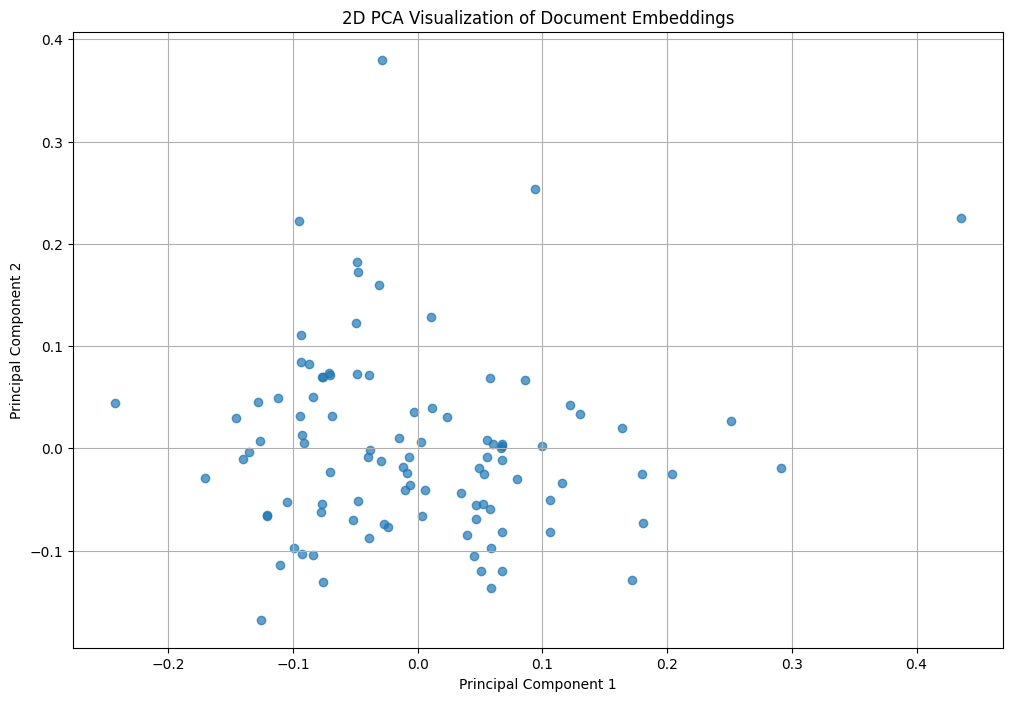

In [37]:
plt.figure(
    figsize=(12, 8)
)

plt.scatter(
    document_vectors_2d[:, 0],
    document_vectors_2d[:, 1],
    alpha=0.7
)

plt.title(
    "2D PCA Visualization of Document Embeddings"
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.grid(True)

plt.show()

## Labeling the documents

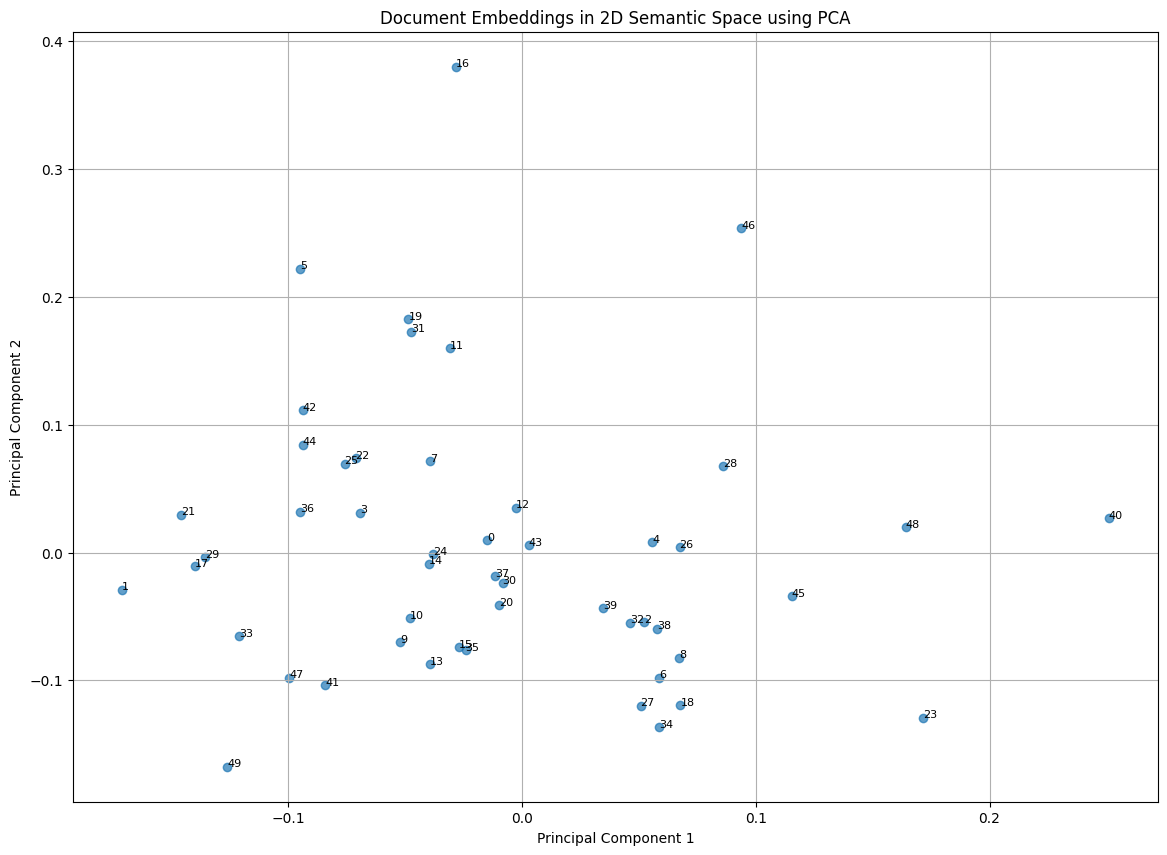

In [38]:
n_label = min(
    50,
    len(document_vectors_2d)
)

plt.figure(
    figsize=(14, 10)
)

plt.scatter(
    document_vectors_2d[:n_label, 0],
    document_vectors_2d[:n_label, 1],
    alpha=0.7
)

for i in range(n_label):

    plt.annotate(
        str(i),
        (
            document_vectors_2d[i, 0],
            document_vectors_2d[i, 1]
        ),
        fontsize=8
    )

plt.title(
    "Document Embeddings in 2D Semantic Space using PCA"
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.grid(True)

plt.show()

## Word Embedding Visualization

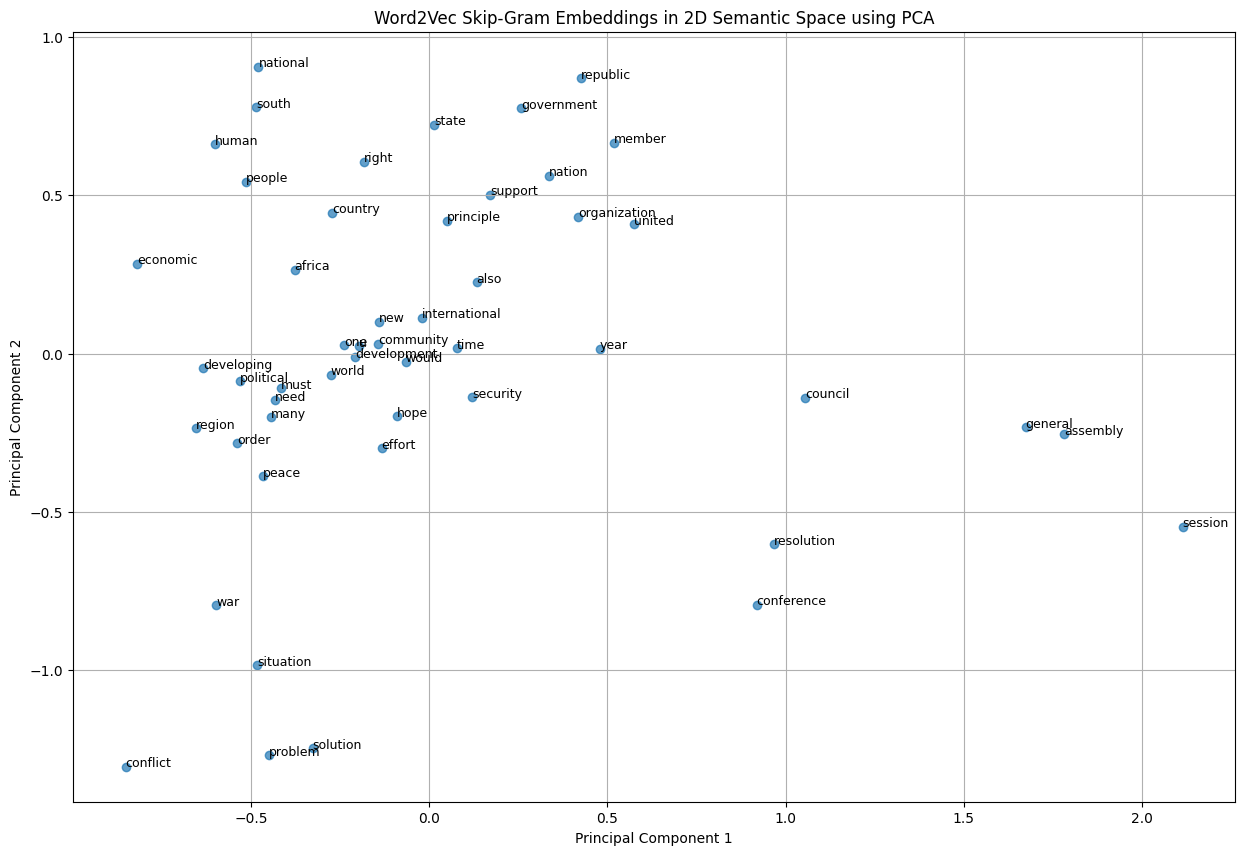

In [39]:
n_words = min(
    50,
    len(word2vec_model.wv.index_to_key)
)

words = (
    word2vec_model.wv.index_to_key[:n_words]
)

word_vectors = np.array([

    word2vec_model.wv[word]

    for word in words
])

# PCA on word embeddings
pca_words = PCA(
    n_components=2
)

word_vectors_2d = pca_words.fit_transform(
    word_vectors
)

# Plot word semantic space
plt.figure(
    figsize=(15, 10)
)

plt.scatter(
    word_vectors_2d[:, 0],
    word_vectors_2d[:, 1],
    alpha=0.7
)

for i, word in enumerate(words):

    plt.annotate(
        word,
        (
            word_vectors_2d[i, 0],
            word_vectors_2d[i, 1]
        ),
        fontsize=9
    )

plt.title(
    "Word2Vec Skip-Gram Embeddings "
    "in 2D Semantic Space using PCA"
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.grid(True)

plt.show()


## PCA Visualization Summary
Principal Component Analysis (PCA) was used to reduce the high-dimensional embeddings to two dimensions. This allows the semantic relationships between documents or words to be visualized in a 2D space.

Documents or words that are located closer together in the visualization have more similar embedding representations, although the 2D visualization is only an approximation of the original high-dimensional semantic space.